<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1682s 10us/step
Train: (8000, 32, 32, 3), Val: (2000, 32, 32, 3), Test: (2000, 32, 32, 3)

[1. Depth] 2 Conv Layers (Baseline)     | Acc: 55.35% | Params: 282,250 | Time: 16.46s
[1. Depth] 3 Conv Layers                | Acc: 57.55% | Params: 225,034 | Time: 14.10s
[1. Depth] 4 Conv Layers                | Acc: 55.30% | Params: 372,618 | Time: 13.97s
[2. Filters] 3x3, Base 16 Filters         | Acc: 53.55% | Params:  89,834 | Time: 26.72s
[2. Filters] 5x5, Base 32 Filters         | Acc: 53.00% | Params: 390,410 | Time: 17.85s
[3. Pool/BN] MaxPool + BatchNorm          | Acc: 50.30% | Params: 225,930 | Time: 17.78s
[3. Pool/BN] AvgPool (No BN)              | Acc: 51.40% | Params: 225,034 | Time: 10.53s
[3. Pool/BN] AvgPool + BatchNorm          | Acc: 58.55% | Params: 225,930 | Time: 12.93s
[4. Hyperparams] LR = 0.0003, BS = 64         | Acc: 51.35% | Params: 225,034 | Time: 11.33s
[4. Hyperparams] LR = 0.003,  BS = 64         | Acc: 50.65% | Params:

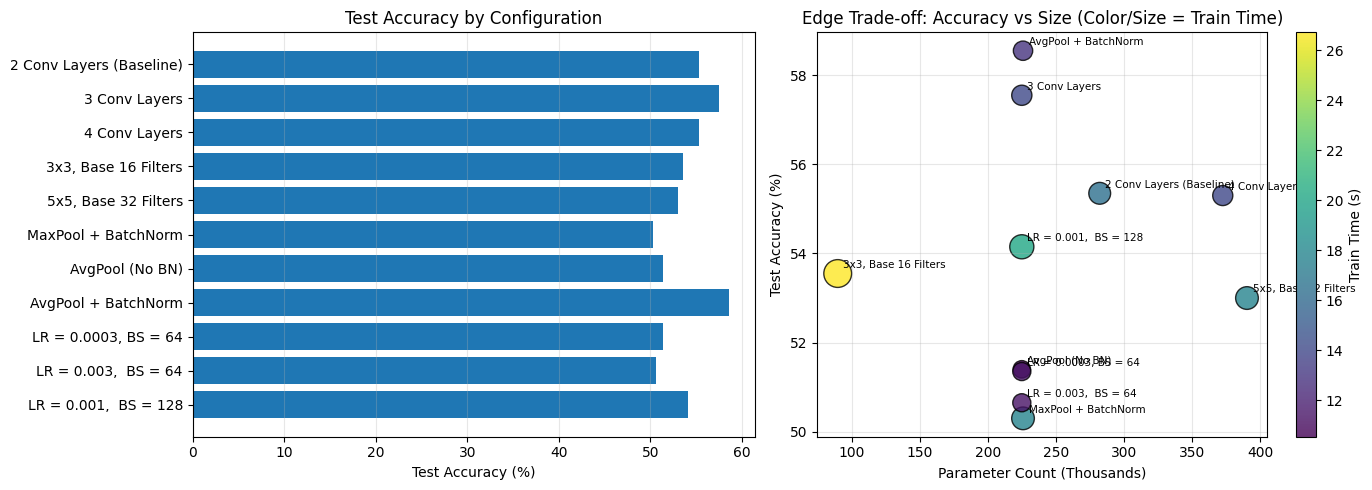

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Load & Prepare CIFAR-10 Dataset
# ==========================================
(X_train_all, y_train_all), (X_test_all, y_test_all) = keras.datasets.cifar10.load_data()

# Balanced subset so all 11 configurations run quickly in Colab
X_sub = X_train_all[:10000].astype("float32") / 255.0
y_sub = y_train_all[:10000].ravel()
X_test = X_test_all[:2000].astype("float32") / 255.0
y_test = y_test_all[:2000].ravel()

X_train, X_val, y_train, y_val = train_test_split(
    X_sub, y_sub, test_size=0.2, random_state=42, stratify=y_sub
)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}\n")

# ==========================================
# Modular CNN Builder & Evaluator
# ==========================================
def build_cnn(num_conv_layers=3, kernel_size=(3, 3), base_filters=32,
              pool_type="max", use_bn=False, lr=1e-3):
    tf.random.set_seed(42)
    model = keras.Sequential([layers.Input(shape=(32, 32, 3))])

    for i in range(num_conv_layers):
        filters = base_filters * (2 ** min(i, 2))  # e.g., 32 -> 64 -> 128
        model.add(layers.Conv2D(filters, kernel_size, padding="same"))
        if use_bn:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))

        # Pool after first 3 conv blocks (keeps spatial dims >= 4x4)
        if i < 3:
            if pool_type == "max":
                model.add(layers.MaxPooling2D((2, 2)))
            else:
                model.add(layers.AveragePooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(10, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

results = []
EPOCHS = 8

def run_experiment(group, name, num_conv_layers=3, kernel_size=(3, 3),
                   base_filters=32, pool_type="max", use_bn=False,
                   lr=1e-3, batch_size=64):
    model = build_cnn(
        num_conv_layers=num_conv_layers,
        kernel_size=kernel_size,
        base_filters=base_filters,
        pool_type=pool_type,
        use_bn=use_bn,
        lr=lr
    )
    start = time.time()
    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=batch_size,
        verbose=0
    )
    elapsed = time.time() - start
    _, test_acc = model.evaluate(X_test, y_test, verbose=0)
    params = model.count_params()

    results.append({
        "Group": group,
        "Configuration": name,
        "Test Acc (%)": round(test_acc * 100, 2),
        "Parameters": params,
        "Train Time (s)": round(elapsed, 2)
    })
    print(f"[{group}] {name:28s} | Acc: {test_acc*100:5.2f}% | Params: {params:7,d} | Time: {elapsed:5.2f}s")

# ==========================================
# Task 1: Vary Number of Conv Layers (2, 3, 4)
# ==========================================
run_experiment("1. Depth", "2 Conv Layers (Baseline)", num_conv_layers=2)
run_experiment("1. Depth", "3 Conv Layers",            num_conv_layers=3)
run_experiment("1. Depth", "4 Conv Layers",            num_conv_layers=4)

# ==========================================
# Task 2: Vary Filter Size (3x3, 5x5) & Filter Count
# ==========================================
run_experiment("2. Filters", "3x3, Base 16 Filters", kernel_size=(3, 3), base_filters=16)
run_experiment("2. Filters", "5x5, Base 32 Filters", kernel_size=(5, 5), base_filters=32)

# ==========================================
# Task 3: Max vs Avg Pooling, With & Without BatchNorm
# ==========================================
run_experiment("3. Pool/BN", "MaxPool + BatchNorm",  pool_type="max", use_bn=True)
run_experiment("3. Pool/BN", "AvgPool (No BN)",      pool_type="avg", use_bn=False)
run_experiment("3. Pool/BN", "AvgPool + BatchNorm",  pool_type="avg", use_bn=True)

# ==========================================
# Task 4: Vary Learning Rate & Batch Size
# ==========================================
run_experiment("4. Hyperparams", "LR = 0.0003, BS = 64", lr=3e-4, batch_size=64)
run_experiment("4. Hyperparams", "LR = 0.003,  BS = 64", lr=3e-3, batch_size=64)
run_experiment("4. Hyperparams", "LR = 0.001,  BS = 128", lr=1e-3, batch_size=128)

# ==========================================
# Task 5: Tabulate Results & Plot Trade-offs
# ==========================================
df_results = pd.DataFrame(results)
print("\n=== CNN Architecture & Hyperparameter Comparison ===")
print(df_results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart: Test Accuracy across configurations
axes[0].barh(df_results["Configuration"], df_results["Test Acc (%)"], color="tab:blue")
axes[0].set_xlabel("Test Accuracy (%)")
axes[0].set_title("Test Accuracy by Configuration")
axes[0].invert_yaxis()
axes[0].grid(True, axis="x", alpha=0.3)

# Scatter plot: Accuracy vs Model Size (bubble size = training time)
scatter = axes[1].scatter(
    df_results["Parameters"] / 1e3,
    df_results["Test Acc (%)"],
    s=df_results["Train Time (s)"] * 15,
    c=df_results["Train Time (s)"],
    cmap="viridis",
    alpha=0.8,
    edgecolors="black"
)
for _, row in df_results.iterrows():
    axes[1].annotate(
        row["Configuration"],
        (row["Parameters"] / 1e3, row["Test Acc (%)"]),
        fontsize=7.5,
        xytext=(4, 4),
        textcoords="offset points"
    )
axes[1].set_xlabel("Parameter Count (Thousands)")
axes[1].set_ylabel("Test Accuracy (%)")
axes[1].set_title("Edge Trade-off: Accuracy vs Size (Color/Size = Train Time)")
axes[1].grid(True, alpha=0.3)
plt.colorbar(scatter, ax=axes[1], label="Train Time (s)")

plt.tight_layout()
plt.show()